# Home Credit | 历史部署回测与概率校准监控

本实验基于 Home Credit 清洗数据和 NB7 的 LightGBM 参考配置，构建一个**假设在 Week 55 部署模型**的历史回放场景。目标是比较模型部署后各周的概率校准、排序能力、统计证据积累及等待期间的业务暴露。

### 研究流程

```text
Week 0–49：内部训练
Week 50–54：确定训练轮数（early stopping）
Week 0–54：按已确定的轮数重新训练并冻结部署模型
Week 55–77：按周监控；不用于训练、调参或学习类别规则
Week 78–91：不使用
```

### 关键边界

- 本实验复用 NB5 的数据清洗结果与 NB7 的参考建模设置，不等同于 NB14 的最终模型选择流程。
- Week 55 的部署时点是为了研究历史阶段差异而设定的回测场景，并非真实部署记录，也并非独立的前瞻验证。
- 模型排序表现、概率校准与业务行动的触发条件是不同问题；统计信号不直接等于需要暂停模型。
- 申请量用于构建业务暴露代理指标，不代表错误决策数或真实金额损失。


# 1. 时间切分与信息边界

为模拟 Week 55 部署，所有影响模型的开发决策均限制在 Week 55 以前。

| 用途 | 时间窗口 | 说明 |
|---|---|---|
| 内部训练 | Week 0–49 | 构建临时 LightGBM 模型 |
| 内部检查 | Week 50–54 | 使用 binary log-loss 确定最佳训练轮数 |
| 最终拟合 | Week 0–54 | 重新学习类别规则并按固定轮数训练 |
| 部署后监控 | Week 55–77 | 只用于历史回测与监控评价 |
| 未使用 | Week 78–91 | 不进入本实验 |

采用不同于 NB7（Train 0–63、Validation 64–77）的切分，是为了避免将模拟部署后的数据用于 early stopping。Week 55 这一回测起点由已观察到的历史阶段差异启发，因此结论仅属于**回顾性案例分析**；不能据此宣称已经验证了未来的漂移检测性能。


# 2. 参考配置与重新训练范围

保留 NB7 中 LightGBM 的预设参考参数：

```text
learning_rate      = 0.05
num_leaves         = 31
feature_fraction   = 0.8
bagging_fraction   = 0.8
bagging_freq       = 1
lambda_l2          = 1.0
max_bin            = 63
bin sample         = 50,000
random seed        = 42
```

**需要重新学习的对象：** 模型参数、类别保留与 rare-category 映射规则、最佳训练轮数；它们必须满足新的时间切分约束。

**复用的上游产物：** NB5 的清洗数据与特征目录，NB7 的候选特征边界与固定参数设置。不重新执行原始表聚合，也不使用后续 NB8–NB14 的特征搜索结果。

以上设计使本实验的核心变量集中在模拟部署时点和监控评价。


In [1]:
# ============================================================
# 3. Colab 环境、路径与 NB7 固定设置
# ============================================================

from pathlib import Path
from collections import Counter
import gc
import json
import shutil
import zipfile

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression

# ------------------------------------------------------------
# 中文图表字体兼容
# ------------------------------------------------------------
# Colab / Matplotlib 的默认字体有时不包含中文字符，
# 会把标题和坐标轴显示成方块。
# 这里优先使用系统里已经存在的中文字体；
# 如果当前运行环境没有中文字体，则图表自动切换成英文标题，
# 不下载额外字体，也不会影响模型结果或运行速度。
from matplotlib import font_manager

_CJK_FONT_CANDIDATES = [
    "Noto Sans CJK SC",
    "Noto Sans CJK JP",
    "Microsoft YaHei",
    "SimHei",
    "Arial Unicode MS",
    "PingFang SC",
]

_available_font_names = {
    font.name
    for font in font_manager.fontManager.ttflist
}

CHART_CJK_FONT = next(
    (
        name
        for name in _CJK_FONT_CANDIDATES
        if name in _available_font_names
    ),
    None,
)

if CHART_CJK_FONT is not None:
    plt.rcParams["font.family"] = CHART_CJK_FONT
    CHART_USE_CHINESE = True
    print("图表中文字体：", CHART_CJK_FONT)
else:
    CHART_USE_CHINESE = False
    print("当前环境没有检测到中文字体；图表将使用英文标题，避免乱码。")

plt.rcParams["axes.unicode_minus"] = False

RANDOM_SEED = 42

ID_COL = "case_id"
TARGET_COL = "target"
WEEK_COL = "WEEK_NUM"

# ------------------------------------------------------------
# 时间边界
# ------------------------------------------------------------

DEV_TRAIN_MIN_WEEK = 0
DEV_TRAIN_MAX_WEEK = 49

DEV_STOP_MIN_WEEK = 50
DEV_STOP_MAX_WEEK = 54

DEPLOY_TRAIN_MIN_WEEK = 0
DEPLOY_TRAIN_MAX_WEEK = 54

MONITOR_MIN_WEEK = 55
MONITOR_MAX_WEEK = 77

# Week 78–91 不读取。

# ------------------------------------------------------------
# 与 NB7 保持一致的类别规则
# ------------------------------------------------------------

CATEGORICAL_COLUMN_BATCH_SIZE = 8

RARE_CATEGORY_MIN_FREQUENCY = 100
MAX_CATEGORIES_PER_FEATURE = 100

MISSING_TOKEN = "__HC_MISSING__"
RARE_TOKEN = "__HC_RARE__"

# NB7 当前正式版本这里为空。
# 如果你以后确认 NB7 有人工排除字段，请把同一名单复制到这里。
MANUAL_EXCLUDE_FEATURES = []

# ------------------------------------------------------------
# 与 NB7 保持一致的 LightGBM 设置
# ------------------------------------------------------------

LGBM_MAX_BOOST_ROUND = 2000
LGBM_EARLY_STOPPING_ROUNDS = 100

LGBM_DEVICE_TYPE = "gpu"
LGBM_MAX_BIN = 63
LGBM_BIN_SAMPLE_COUNT = 50_000

LGBM_PARAMS = {
    "objective": "binary",
    "metric": [
        "binary_logloss",
        "auc",
    ],
    "learning_rate": 0.05,
    "num_leaves": 31,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 1.0,
    "seed": RANDOM_SEED,
    "device_type": LGBM_DEVICE_TYPE,
    "verbosity": -1,
    "num_threads": -1,
}

# ------------------------------------------------------------
# Colab + Drive
# ------------------------------------------------------------

try:
    from google.colab import drive
except ImportError as exc:
    raise RuntimeError(
        "这一本 Notebook 按 Google Colab + Google Drive 编写。"
    ) from exc

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/HomeCredit_Project"
)

ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"

REPORT_ROOT = (
    ARTIFACT_ROOT
    / "fit5145"
    / "nb02_history_backtest"
)

REPORT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

LOCAL_INPUT_ROOT = Path(
    "/content/fit5145_nb02_input"
)

LOCAL_INPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

print("输出目录：", REPORT_ROOT)

Mounted at /content/drive
输出目录： /content/drive/MyDrive/HomeCredit_Project/artifacts/fit5145/nb02_history_backtest


# 4. 读取 NB5 已清洗数据

从 NB5 读取以下已清洗产物：

```text
train_clean.parquet       → Week 0–63
validation_clean.parquet  → Week 64–77
feature_catalog.csv       → 字段角色
```

本实验不重新执行原始表连接。

回测时间窗口进一步划分为：

```text
0–49
50–54
0–54
55–77
```

后面的代码不会真的把两张大表一次性全部合并进内存，而是继续按 Parquet row group 读取。


In [2]:
# ============================================================
# 4.1 自动寻找并缓存 NB5 输入
# ============================================================

required_nb5_files = {
    "train_clean.parquet",
    "validation_clean.parquet",
    "feature_catalog.csv",
}


def _contains_required_files(directory):
    directory = Path(directory)

    if (
        not directory.exists()
        or not directory.is_dir()
    ):
        return False

    names = {
        path.name
        for path in directory.iterdir()
        if path.is_file()
    }

    return required_nb5_files.issubset(names)


def _find_nb5_source_dir():

    preferred = [
        ARTIFACT_ROOT / "nb05" / "final",
        ARTIFACT_ROOT / "nb05",
        PROJECT_ROOT / "clean_split",
        (
            ARTIFACT_ROOT
            / "_auto_extracted"
            / "Notebook_5"
            / "nb05_clean_split_outputs"
            / "clean_split"
        ),
    ]

    for candidate in preferred:
        if _contains_required_files(candidate):
            return candidate

    # 如果 Drive 上只有 zip，则解压到 Colab 本地。
    zip_candidates = list(
        ARTIFACT_ROOT.rglob(
            "nb05_clean_split_outputs.zip"
        )
    )

    if not zip_candidates:
        zip_candidates = [
            p
            for p in ARTIFACT_ROOT.rglob("*.zip")
            if (
                "nb05" in p.name.lower()
                or "notebook_5" in str(p).lower()
            )
        ]

    for zip_path in zip_candidates:
        try:
            with zipfile.ZipFile(
                zip_path,
                "r",
            ) as zf:

                members = zf.namelist()
                parent_to_names = {}

                for member in members:
                    member_path = Path(member)
                    parent = str(
                        member_path.parent
                    )

                    parent_to_names.setdefault(
                        parent,
                        set(),
                    ).add(
                        member_path.name
                    )

                matching = [
                    parent
                    for parent, names
                    in parent_to_names.items()
                    if required_nb5_files.issubset(
                        names
                    )
                ]

                if not matching:
                    continue

                extract_root = (
                    LOCAL_INPUT_ROOT
                    / "nb05_extracted"
                )

                extract_root.mkdir(
                    parents=True,
                    exist_ok=True,
                )

                zf.extractall(
                    extract_root
                )

                resolved = (
                    extract_root
                    / matching[0]
                )

                if _contains_required_files(
                    resolved
                ):
                    return resolved

        except zipfile.BadZipFile:
            continue

    raise FileNotFoundError(
        "没有找到 NB5 的 train_clean.parquet、"
        "validation_clean.parquet 和 feature_catalog.csv。"
    )


NB5_SOURCE_DIR = _find_nb5_source_dir()

print("NB5 来源：", NB5_SOURCE_DIR)


def _cache_to_local(source_path):

    source_path = Path(source_path)

    destination = (
        LOCAL_INPUT_ROOT
        / source_path.name
    )

    if (
        not destination.exists()
        or destination.stat().st_size
        != source_path.stat().st_size
    ):
        print(
            "缓存到 Colab 本地：",
            source_path.name,
        )

        shutil.copy2(
            source_path,
            destination,
        )

    return destination


TRAIN_PATH = _cache_to_local(
    NB5_SOURCE_DIR
    / "train_clean.parquet"
)

VALIDATION_PATH = _cache_to_local(
    NB5_SOURCE_DIR
    / "validation_clean.parquet"
)

FEATURE_CATALOG_PATH = _cache_to_local(
    NB5_SOURCE_DIR
    / "feature_catalog.csv"
)

print("Train：", TRAIN_PATH)
print("Validation：", VALIDATION_PATH)

NB5 来源： /content/drive/MyDrive/HomeCredit_Project/artifacts/_auto_extracted/Notebook_5/nb05_clean_split_outputs/clean_split
缓存到 Colab 本地： train_clean.parquet
缓存到 Colab 本地： validation_clean.parquet
缓存到 Colab 本地： feature_catalog.csv
Train： /content/fit5145_nb02_input/train_clean.parquet
Validation： /content/fit5145_nb02_input/validation_clean.parquet


# 5. 继续使用 NB7 的合法候选特征池

此处只做候选特征边界检查，不进行新的预测型特征选择。

保留 NB7 使用的基本约束：

- ID 不进入模型；
- target 不进入模型；
- WEEK_NUM 不进入模型；
- 只保留 `model_feature`；
- 只接受 numerical / categorical / boolean；
- 人工确认的泄漏字段继续排除。

> **这仍然是 NB7 的 raw candidate feature pool 思路，不是 NB10 的最终特征子集。**

原因是：

> 本实验要改变的是“部署时间”，不是重新优化模型。


In [3]:
# ============================================================
# 5.1 构建与 NB7 一致的 candidate feature pool
# ============================================================

feature_catalog = pd.read_csv(
    FEATURE_CATALOG_PATH
)

required_cols = {
    "column",
    "dtype",
    "dtype_family",
    "role",
    "origin",
}

missing_cols = (
    required_cols
    - set(feature_catalog.columns)
)

assert not missing_cols, (
    f"feature_catalog 缺少："
    f"{sorted(missing_cols)}"
)

unknown_exclusions = (
    set(MANUAL_EXCLUDE_FEATURES)
    - set(feature_catalog["column"])
)

assert not unknown_exclusions, (
    "MANUAL_EXCLUDE_FEATURES "
    f"存在未知字段：{sorted(unknown_exclusions)}"
)

model_catalog = (
    feature_catalog
    .loc[
        feature_catalog["role"]
        .eq("model_feature")
    ]
    .copy()
)

supported_types = {
    "numeric",
    "categorical",
    "boolean",
}

candidate_catalog = (
    model_catalog
    .loc[
        model_catalog[
            "dtype_family"
        ].isin(
            supported_types
        )
    ]
    .loc[
        lambda frame:
        ~frame["column"].isin(
            MANUAL_EXCLUDE_FEATURES
        )
    ]
    .copy()
)

candidate_features = (
    candidate_catalog["column"]
    .tolist()
)

numeric_features = (
    candidate_catalog
    .loc[
        candidate_catalog[
            "dtype_family"
        ].eq("numeric"),
        "column",
    ]
    .tolist()
)

categorical_features = (
    candidate_catalog
    .loc[
        candidate_catalog[
            "dtype_family"
        ].isin(
            [
                "categorical",
                "boolean",
            ]
        ),
        "column",
    ]
    .tolist()
)

for forbidden in [
    ID_COL,
    TARGET_COL,
    WEEK_COL,
]:
    assert (
        forbidden
        not in candidate_features
    )

print(
    "全部合法 raw candidate features：",
    len(candidate_features),
)

print(
    "Numerical：",
    len(numeric_features),
)

print(
    "Categorical / Boolean：",
    len(categorical_features),
)

display(
    candidate_catalog[
        [
            "column",
            "dtype_family",
            "origin",
        ]
    ].head(20)
)

全部合法 raw candidate features： 1209
Numerical： 1150
Categorical / Boolean： 59


,column,dtype_family,origin
5,actualdpdtolerance_344P,numeric,original
6,amtinstpaidbefduel24m_4187115A,numeric,original
7,annuity_780A,numeric,original
8,annuitynextmonth_57A,numeric,original
9,applicationcnt_361L,numeric,original
10,applications30d_658L,numeric,original
11,applicationscnt_1086L,numeric,original
12,applicationscnt_464L,numeric,original
13,applicationscnt_629L,numeric,original
14,applicationscnt_867L,numeric,original


# 6. 时间边界校验

训练前检查 `WEEK_NUM`、`target`、`case_id` 在清洗数据中的取值范围，验证 Train 不超过 Week 63、Validation 覆盖 Week 64–77。本实验进一步在数据读取器中限制实际可使用的周数，确保 Week 55–77 未进入拟合与 early stopping。


In [4]:
# ============================================================
# 6.1 时间结构审查
# ============================================================

def read_time_summary(path, name):
    frame = pd.read_parquet(
        path,
        columns=[
            ID_COL,
            WEEK_COL,
            TARGET_COL,
        ],
        engine="pyarrow",
    )

    out = {
        "dataset": name,
        "rows": len(frame),
        "min_week": int(
            frame[WEEK_COL].min()
        ),
        "max_week": int(
            frame[WEEK_COL].max()
        ),
        "bad_rate": float(
            frame[TARGET_COL].mean()
        ),
    }

    del frame
    gc.collect()

    return out


time_summary = pd.DataFrame([
    read_time_summary(
        TRAIN_PATH,
        "NB5 Train",
    ),
    read_time_summary(
        VALIDATION_PATH,
        "NB5 Validation",
    ),
])

display(time_summary)

assert (
    time_summary
    .loc[
        time_summary["dataset"]
        .eq("NB5 Train"),
        "max_week",
    ]
    .iloc[0]
    <= 63
)

assert (
    time_summary
    .loc[
        time_summary["dataset"]
        .eq("NB5 Validation"),
        "min_week",
    ]
    .iloc[0]
    >= 64
)

assert MONITOR_MAX_WEEK <= 77

print(
    "时间边界通过："
    "Week 78–91 未进入本 Notebook。"
)

,dataset,rows,min_week,max_week,bad_rate
0,NB5 Train,1282082,0,63,0.033168
1,NB5 Validation,92870,64,77,0.024281


时间边界通过：Week 78–91 未进入本 Notebook。


# 7. 类别规则必须重新学习

LightGBM 的 numerical 特征可以直接保留原始数值和 NaN。

但 categorical / boolean 需要先把低频类别统一映射到：

```text
__HC_RARE__
```

因此类别规则属于：

> **从训练时期学出来的东西。**

不能直接拿 NB7 用 Week 0–63 学出来的规则。

按不同拟合阶段分别学习两套类别规则：

### 临时开发规则

```text
只从 Week 0–49 学
```

用于：

```text
0–49 训练
50–54 early stopping
```

### 最终部署规则

```text
从 Week 0–54 学
```

因为真正部署发生在 Week 55，此时 0–54 都已经属于过去。

这两套规则都不会读取 Week 55–77。


In [5]:
# ============================================================
# 7.1 从指定历史窗口学习 categorical rules
# ============================================================

def _iter_filtered_frames(
    paths,
    columns,
    min_week,
    max_week,
):
    """
    逐 row group 读取，
    只返回指定 Week 范围。
    """

    for path in paths:

        parquet = pq.ParquetFile(
            path
        )

        for row_group_id in range(
            parquet.num_row_groups
        ):

            frame = (
                parquet
                .read_row_group(
                    row_group_id,
                    columns=[
                        WEEK_COL,
                        *columns,
                    ],
                    use_threads=True,
                )
                .to_pandas()
            )

            mask = (
                frame[WEEK_COL]
                .between(
                    min_week,
                    max_week,
                )
            )

            if mask.any():
                yield (
                    frame
                    .loc[
                        mask,
                        columns,
                    ]
                    .reset_index(drop=True)
                )

            del frame


def learn_categorical_rules(
    paths,
    features,
    min_week,
    max_week,
):
    """
    只使用指定过去时间窗口，
    学习低频类别和最终 category code 空间。
    """

    rules = {}
    summary_rows = []

    for start in range(
        0,
        len(features),
        CATEGORICAL_COLUMN_BATCH_SIZE,
    ):

        batch_features = features[
            start:
            start
            + CATEGORICAL_COLUMN_BATCH_SIZE
        ]

        counters = {
            feature: Counter()
            for feature
            in batch_features
        }

        total_rows = {
            feature: 0
            for feature
            in batch_features
        }

        missing_rows = {
            feature: 0
            for feature
            in batch_features
        }

        for frame in _iter_filtered_frames(
            paths=paths,
            columns=batch_features,
            min_week=min_week,
            max_week=max_week,
        ):

            for feature in batch_features:

                series = (
                    frame[feature]
                    .astype("string")
                    .fillna(
                        MISSING_TOKEN
                    )
                )

                total_rows[
                    feature
                ] += len(series)

                missing_rows[
                    feature
                ] += int(
                    series
                    .eq(MISSING_TOKEN)
                    .sum()
                )

                counters[
                    feature
                ].update(
                    series.tolist()
                )

            del frame
            gc.collect()

        for feature in batch_features:

            counts = counters[
                feature
            ]

            normal_items = [
                (category, count)
                for category, count
                in counts.items()
                if (
                    category
                    != MISSING_TOKEN
                )
            ]

            frequent = [
                (category, count)
                for category, count
                in normal_items
                if (
                    count
                    >= RARE_CATEGORY_MIN_FREQUENCY
                )
            ]

            frequent.sort(
                key=lambda item: (
                    -item[1],
                    str(item[0]),
                )
            )

            normal_limit = max(
                0,
                MAX_CATEGORIES_PER_FEATURE
                - 2,
            )

            kept_normal = [
                str(category)
                for category, _
                in frequent[
                    :normal_limit
                ]
            ]

            categories = [
                *kept_normal,
                MISSING_TOKEN,
                RARE_TOKEN,
            ]

            rules[feature] = {
                "categories": categories,
                "kept_set": set(
                    categories
                ),
            }

            summary_rows.append({
                "feature": feature,
                "time_window": (
                    f"{min_week}-{max_week}"
                ),
                "raw_unique_count": (
                    len(counts)
                ),
                "kept_normal_count": (
                    len(kept_normal)
                ),
                "final_category_count": (
                    len(categories)
                ),
                "missing_rate": (
                    missing_rows[feature]
                    / max(
                        total_rows[feature],
                        1,
                    )
                ),
            })

        finished = min(
            start
            + len(batch_features),
            len(features),
        )

        print(
            f"类别规则："
            f"{finished:,} / "
            f"{len(features):,}"
        )

    return (
        rules,
        pd.DataFrame(
            summary_rows
        ),
    )

In [6]:
# ============================================================
# 7.2 临时开发规则：只允许看 Week 0–49
# ============================================================

dev_categorical_rules, dev_category_summary = (
    learn_categorical_rules(
        paths=[
            TRAIN_PATH,
        ],
        features=categorical_features,
        min_week=DEV_TRAIN_MIN_WEEK,
        max_week=DEV_TRAIN_MAX_WEEK,
    )
)

display(
    dev_category_summary.head()
)

assert (
    dev_category_summary[
        "time_window"
    ]
    .eq("0-49")
    .all()
)

类别规则：8 / 59
类别规则：16 / 59
类别规则：24 / 59
类别规则：32 / 59
类别规则：40 / 59
类别规则：48 / 59
类别规则：56 / 59
类别规则：59 / 59


,feature,time_window,raw_unique_count,kept_normal_count,final_category_count,missing_rate
0,cardtype_51L,0-49,3,2,4,8.746868e-01
1,credtype_322L,0-49,4,3,5,9.962571e-07
2,disbursementtype_67L,0-49,4,3,5,6.156869e-04
3,equalitydataagreement_891L,0-49,3,2,4,9.478838e-01
4,equalityempfrom_62L,0-49,3,2,4,9.717013e-01


# 8. 构造一个“按 Week 过滤”的 LightGBM 数据读取器

NB7 的实验显示：

> 全量宽表一次性展开到 Pandas 很容易占太多内存。

因此继续采用分块读取。

每个 Parquet row group 还会根据以下列进行周过滤：

```text
WEEK_NUM
```

过滤出合法时间范围。

例如临时训练对象只会返回：

```text
Week 0–49
```

而不会因为原始 `train_clean.parquet` 里面还存在 50–63 就把它们一起送给模型。


In [7]:
# ============================================================
# 8.1 Filtered LightGBM Sequence
# ============================================================

import lightgbm as lgb


class FilteredMultiParquetSequence(
    lgb.Sequence
):
    """
    支持：
    - 多个 Parquet 文件
    - Week 过滤
    - LightGBM numerical 原始值
    - categorical / boolean 使用冻结规则编码
    """

    batch_size = 4096

    def __init__(
        self,
        paths,
        min_week,
        max_week,
        numeric_features,
        categorical_features,
        categorical_rules,
    ):

        self.paths = [
            Path(p)
            for p in paths
        ]

        self.min_week = int(
            min_week
        )
        self.max_week = int(
            max_week
        )

        self.numeric_features = list(
            numeric_features
        )

        self.categorical_features = list(
            categorical_features
        )

        self.categorical_rules = (
            categorical_rules
        )

        self.feature_columns = [
            *self.numeric_features,
            *self.categorical_features,
        ]

        self.parquets = [
            pq.ParquetFile(path)
            for path in self.paths
        ]

        self.segments = []

        # 每个 segment =
        # (file_id, row_group_id, local_positions)
        for file_id, parquet in enumerate(
            self.parquets
        ):

            for row_group_id in range(
                parquet.num_row_groups
            ):

                week_frame = (
                    parquet
                    .read_row_group(
                        row_group_id,
                        columns=[
                            WEEK_COL,
                        ],
                        use_threads=True,
                    )
                    .to_pandas()
                )

                weeks = (
                    week_frame[
                        WEEK_COL
                    ]
                    .to_numpy()
                )

                positions = np.flatnonzero(
                    (
                        weeks
                        >= self.min_week
                    )
                    & (
                        weeks
                        <= self.max_week
                    )
                ).astype(
                    np.int32
                )

                if len(
                    positions
                ) > 0:

                    self.segments.append(
                        (
                            file_id,
                            row_group_id,
                            positions,
                        )
                    )

                del (
                    week_frame,
                    weeks,
                )

        self.segment_sizes = np.array(
            [
                len(segment[2])
                for segment
                in self.segments
            ],
            dtype=np.int64,
        )

        self.segment_starts = (
            np.concatenate([
                np.array(
                    [0],
                    dtype=np.int64,
                ),
                np.cumsum(
                    self.segment_sizes
                ),
            ])
        )

        self.total_rows = int(
            self.segment_starts[-1]
        )

        self._cache_segment_id = None
        self._cache_matrix = None

        if self.total_rows == 0:
            raise ValueError(
                f"Week {min_week}-{max_week} "
                "没有找到任何样本。"
            )

    def __len__(self):
        return self.total_rows

    def _convert_segment(
        self,
        segment_id,
    ):

        (
            file_id,
            row_group_id,
            positions,
        ) = self.segments[
            segment_id
        ]

        parquet = self.parquets[
            file_id
        ]

        frame = (
            parquet
            .read_row_group(
                int(
                    row_group_id
                ),
                columns=(
                    self.feature_columns
                ),
                use_threads=True,
            )
            .to_pandas()
            .iloc[
                positions
            ]
            .reset_index(
                drop=True
            )
        )

        # -----------------------------
        # Numerical
        # -----------------------------
        numerical = (
            frame[
                self.numeric_features
            ]
            .to_numpy(
                dtype=np.float32,
                na_value=np.nan,
            )
        )

        # -----------------------------
        # Categorical
        # -----------------------------
        categorical_arrays = []

        for feature in (
            self.categorical_features
        ):

            series = (
                frame[feature]
                .astype("string")
                .fillna(
                    MISSING_TOKEN
                )
            )

            rule = (
                self.categorical_rules[
                    feature
                ]
            )

            series = series.where(
                series.isin(
                    rule[
                        "kept_set"
                    ]
                ),
                RARE_TOKEN,
            )

            codes = (
                pd.Categorical(
                    series,
                    categories=rule[
                        "categories"
                    ],
                )
                .codes
                .astype(
                    np.float32
                )
            )

            # 理论上不会出现 -1，
            # 因为未知类别已经映射到 RARE。
            if (
                codes < 0
            ).any():
                raise ValueError(
                    f"{feature} "
                    "出现无法编码类别。"
                )

            categorical_arrays.append(
                codes
            )

        if categorical_arrays:
            categorical_matrix = (
                np.column_stack(
                    categorical_arrays
                )
                .astype(
                    np.float32,
                    copy=False,
                )
            )

            matrix = np.hstack([
                numerical,
                categorical_matrix,
            ])

        else:
            matrix = numerical

        del frame

        return np.asarray(
            matrix,
            dtype=np.float32,
            order="C",
        )

    def _get_segment(
        self,
        segment_id,
    ):

        if (
            self._cache_segment_id
            != segment_id
        ):

            self._cache_matrix = (
                self._convert_segment(
                    segment_id
                )
            )

            self._cache_segment_id = (
                segment_id
            )

        return self._cache_matrix

    def _locate(
        self,
        global_index,
    ):

        segment_id = int(
            np.searchsorted(
                self.segment_starts[
                    1:
                ],
                global_index,
                side="right",
            )
        )

        local_index = int(
            global_index
            - self.segment_starts[
                segment_id
            ]
        )

        return (
            segment_id,
            local_index,
        )

    def __getitem__(
        self,
        idx,
    ):

        if isinstance(
            idx,
            (int, np.integer),
        ):

            if idx < 0:
                idx += len(self)

            segment_id, local_index = (
                self._locate(
                    int(idx)
                )
            )

            matrix = (
                self._get_segment(
                    segment_id
                )
            )

            return matrix[
                local_index
            ].astype(
                np.float64,
                copy=False,
            )

        if isinstance(
            idx,
            slice,
        ):

            start = (
                0
                if idx.start is None
                else int(idx.start)
            )

            stop = (
                len(self)
                if idx.stop is None
                else int(idx.stop)
            )

            step = (
                1
                if idx.step is None
                else int(idx.step)
            )

            if step != 1:
                return self[
                    np.arange(
                        start,
                        stop,
                        step,
                    )
                ]

            parts = []
            current = start

            while current < stop:

                (
                    segment_id,
                    local_start,
                ) = self._locate(
                    current
                )

                matrix = (
                    self._get_segment(
                        segment_id
                    )
                )

                available = (
                    len(matrix)
                    - local_start
                )

                take = min(
                    available,
                    stop - current,
                )

                parts.append(
                    matrix[
                        local_start:
                        local_start
                        + take
                    ]
                )

                current += take

            if not parts:
                return np.empty(
                    (
                        0,
                        len(
                            self.feature_columns
                        ),
                    ),
                    dtype=np.float32,
                )

            if len(parts) == 1:
                return parts[0]

            return np.vstack(
                parts
            )

        if isinstance(
            idx,
            (list, np.ndarray),
        ):

            return np.stack([
                self[int(i)]
                for i in idx
            ])

        raise TypeError(
            f"不支持的 index 类型："
            f"{type(idx)}"
        )

In [8]:
# ============================================================
# 8.2 提取与 Sequence 顺序完全一致的标签 / 元数据
# ============================================================

def extract_filtered_metadata(
    paths,
    min_week,
    max_week,
):
    parts = []

    for path in paths:

        parquet = pq.ParquetFile(
            path
        )

        for row_group_id in range(
            parquet.num_row_groups
        ):

            frame = (
                parquet
                .read_row_group(
                    row_group_id,
                    columns=[
                        ID_COL,
                        WEEK_COL,
                        TARGET_COL,
                    ],
                    use_threads=True,
                )
                .to_pandas()
            )

            mask = (
                frame[WEEK_COL]
                .between(
                    min_week,
                    max_week,
                )
            )

            if mask.any():

                parts.append(
                    frame
                    .loc[
                        mask,
                        [
                            ID_COL,
                            WEEK_COL,
                            TARGET_COL,
                        ],
                    ]
                    .reset_index(
                        drop=True
                    )
                )

            del frame

    if not parts:
        raise ValueError(
            f"Week {min_week}-{max_week} "
            "没有样本。"
        )

    output = pd.concat(
        parts,
        ignore_index=True,
    )

    return output

# 9. 内部开发：只用 Week 0–49 训练，Week 50–54 决定训练轮数

内部开发阶段确定：

```text
best_iteration
```

该临时模型不作为最终部署模型。

流程：

```text
Week 0–49
    ↓
临时 LightGBM
    ↓
每一轮观察 Week 50–54 的 binary log-loss
    ↓
连续 100 轮不再改善
    ↓
得到 best_iteration
```

主指标选择 binary log-loss 的原因

本实验重点评价：

> **概率是否可信。**

AUC 仍然同时记录，但不是 early stopping 的第一指标。


In [9]:
# ============================================================
# 9.1 构造内部 Train / Stop 数据
# ============================================================

lgbm_feature_names = [
    *numeric_features,
    *categorical_features,
]

lgbm_categorical_indices = list(
    range(
        len(numeric_features),
        len(lgbm_feature_names),
    )
)

dev_train_sequence = (
    FilteredMultiParquetSequence(
        paths=[
            TRAIN_PATH,
        ],
        min_week=DEV_TRAIN_MIN_WEEK,
        max_week=DEV_TRAIN_MAX_WEEK,
        numeric_features=numeric_features,
        categorical_features=categorical_features,
        categorical_rules=dev_categorical_rules,
    )
)

dev_stop_sequence = (
    FilteredMultiParquetSequence(
        paths=[
            TRAIN_PATH,
        ],
        min_week=DEV_STOP_MIN_WEEK,
        max_week=DEV_STOP_MAX_WEEK,
        numeric_features=numeric_features,
        categorical_features=categorical_features,
        categorical_rules=dev_categorical_rules,
    )
)

dev_train_meta = (
    extract_filtered_metadata(
        paths=[
            TRAIN_PATH,
        ],
        min_week=DEV_TRAIN_MIN_WEEK,
        max_week=DEV_TRAIN_MAX_WEEK,
    )
)

dev_stop_meta = (
    extract_filtered_metadata(
        paths=[
            TRAIN_PATH,
        ],
        min_week=DEV_STOP_MIN_WEEK,
        max_week=DEV_STOP_MAX_WEEK,
    )
)

assert (
    len(dev_train_sequence)
    == len(dev_train_meta)
)

assert (
    len(dev_stop_sequence)
    == len(dev_stop_meta)
)

assert (
    dev_train_meta[
        WEEK_COL
    ].max()
    <= 49
)

assert (
    dev_stop_meta[
        WEEK_COL
    ].min()
    >= 50
)

assert (
    dev_stop_meta[
        WEEK_COL
    ].max()
    <= 54
)

print(
    "0–49 临时训练样本：",
    f"{len(dev_train_meta):,}",
)

print(
    "50–54 内部检查样本：",
    f"{len(dev_stop_meta):,}",
)

0–49 临时训练样本： 1,003,757
50–54 内部检查样本： 126,013


In [10]:
# ============================================================
# 9.2 内部 early stopping
# ============================================================

lgbm_dataset_params = {
    "bin_construct_sample_cnt": (
        LGBM_BIN_SAMPLE_COUNT
    ),
    "max_bin": LGBM_MAX_BIN,
    "data_random_seed": RANDOM_SEED,
}

dev_train_dataset = lgb.Dataset(
    dev_train_sequence,
    label=(
        dev_train_meta[
            TARGET_COL
        ]
        .to_numpy(
            dtype=np.int8
        )
    ),
    feature_name=lgbm_feature_names,
    categorical_feature=(
        lgbm_categorical_indices
    ),
    free_raw_data=True,
    params=lgbm_dataset_params,
)

dev_stop_dataset = lgb.Dataset(
    dev_stop_sequence,
    label=(
        dev_stop_meta[
            TARGET_COL
        ]
        .to_numpy(
            dtype=np.int8
        )
    ),
    reference=dev_train_dataset,
    feature_name=lgbm_feature_names,
    categorical_feature=(
        lgbm_categorical_indices
    ),
    free_raw_data=True,
)

dev_evals_result = {}


def train_dev_model(
    params,
):
    return lgb.train(
        params=params,
        train_set=dev_train_dataset,
        num_boost_round=(
            LGBM_MAX_BOOST_ROUND
        ),
        valid_sets=[
            dev_stop_dataset,
            dev_train_dataset,
        ],
        valid_names=[
            "Internal_50_54",
            "Train_0_49",
        ],
        callbacks=[
            lgb.early_stopping(
                stopping_rounds=(
                    LGBM_EARLY_STOPPING_ROUNDS
                ),
                first_metric_only=True,
                verbose=True,
            ),
            lgb.record_evaluation(
                dev_evals_result
            ),
            lgb.log_evaluation(
                period=50
            ),
        ],
    )


try:
    dev_model = train_dev_model(
        LGBM_PARAMS
    )

except Exception as exc:
    # 某些 Colab 环境的 LightGBM wheel
    # 可能不支持 GPU。
    # 只在 GPU 初始化失败时退回 CPU，
    # 模型参数本身不重新调。
    print(
        "GPU 训练失败，改用 CPU。"
    )
    print(
        "原始错误：",
        str(exc)[:500],
    )

    LGBM_PARAMS = {
        **LGBM_PARAMS,
        "device_type": "cpu",
    }

    dev_evals_result = {}

    dev_model = train_dev_model(
        LGBM_PARAMS
    )


BEST_ITERATION = int(
    dev_model.best_iteration
)

print()
print(
    "内部 early stopping 得到："
)
print(
    "best_iteration =",
    BEST_ITERATION,
)

assert BEST_ITERATION > 0

[LightGBM] [Warning] Using too small ``bin_construct_sample_cnt`` may encounter unexpected errors and poor accuracy.


/usr/local/lib/python3.13/dist-packages/lightgbm/basic.py:2535: UserWarning: Overriding the parameters from Reference Dataset.
  _log_warning("Overriding the parameters from Reference Dataset.")


Training until validation scores don't improve for 100 rounds
[50]	Train_0_49's binary_logloss: 0.114982	Train_0_49's auc: 0.835285	Internal_50_54's binary_logloss: 0.131906	Internal_50_54's auc: 0.822697
[100]	Train_0_49's binary_logloss: 0.10947	Train_0_49's auc: 0.856353	Internal_50_54's binary_logloss: 0.127755	Internal_50_54's auc: 0.837514
[150]	Train_0_49's binary_logloss: 0.106302	Train_0_49's auc: 0.867886	Internal_50_54's binary_logloss: 0.126177	Internal_50_54's auc: 0.84272
[200]	Train_0_49's binary_logloss: 0.103906	Train_0_49's auc: 0.876628	Internal_50_54's binary_logloss: 0.125326	Internal_50_54's auc: 0.845564
[250]	Train_0_49's binary_logloss: 0.101974	Train_0_49's auc: 0.883543	Internal_50_54's binary_logloss: 0.124942	Internal_50_54's auc: 0.846697
[300]	Train_0_49's binary_logloss: 0.100279	Train_0_49's auc: 0.889319	Internal_50_54's binary_logloss: 0.124649	Internal_50_54's auc: 0.847733
[350]	Train_0_49's binary_logloss: 0.0988006	Train_0_49's auc: 0.894461	Inter

# 10. Week 55 模拟部署模型的最终训练

在 Week 0–49 / 50–54 上确定 `best_iteration` 后：

1. 只用 Week 0–54 学习类别规则；
2. 在 Week 0–54 全部样本上重新训练；
3. 固定训练轮数，不再根据 Week 55–77 的表现进行模型选择。

由此得到用于历史回测的冻结参考模型。


In [11]:
# ============================================================
# 10.1 最终 categorical rules：只从 Week 0–54 学
# ============================================================

final_categorical_rules, final_category_summary = (
    learn_categorical_rules(
        paths=[
            TRAIN_PATH,
        ],
        features=categorical_features,
        min_week=DEPLOY_TRAIN_MIN_WEEK,
        max_week=DEPLOY_TRAIN_MAX_WEEK,
    )
)

display(
    final_category_summary.head()
)

assert (
    final_category_summary[
        "time_window"
    ]
    .eq("0-54")
    .all()
)

# 保存最终类别规则，方便以后复现。
final_rules_json = {
    feature: (
        final_categorical_rules[
            feature
        ][
            "categories"
        ]
    )
    for feature
    in categorical_features
}

with open(
    REPORT_ROOT
    / "final_categorical_rules.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        final_rules_json,
        f,
        ensure_ascii=False,
        indent=2,
    )

类别规则：8 / 59
类别规则：16 / 59
类别规则：24 / 59
类别规则：32 / 59
类别规则：40 / 59
类别规则：48 / 59
类别规则：56 / 59
类别规则：59 / 59


,feature,time_window,raw_unique_count,kept_normal_count,final_category_count,missing_rate
0,cardtype_51L,0-54,3,2,4,8.699293e-01
1,credtype_322L,0-54,4,3,5,8.851359e-07
2,disbursementtype_67L,0-54,4,3,5,5.470140e-04
3,equalitydataagreement_891L,0-54,3,2,4,9.480611e-01
4,equalityempfrom_62L,0-54,3,2,4,9.711039e-01


In [12]:
# ============================================================
# 10.2 Week 0–54 最终训练
# ============================================================

deploy_train_sequence = (
    FilteredMultiParquetSequence(
        paths=[
            TRAIN_PATH,
        ],
        min_week=DEPLOY_TRAIN_MIN_WEEK,
        max_week=DEPLOY_TRAIN_MAX_WEEK,
        numeric_features=numeric_features,
        categorical_features=categorical_features,
        categorical_rules=final_categorical_rules,
    )
)

deploy_train_meta = (
    extract_filtered_metadata(
        paths=[
            TRAIN_PATH,
        ],
        min_week=DEPLOY_TRAIN_MIN_WEEK,
        max_week=DEPLOY_TRAIN_MAX_WEEK,
    )
)

assert (
    len(deploy_train_sequence)
    == len(deploy_train_meta)
)

assert (
    deploy_train_meta[
        WEEK_COL
    ].max()
    <= 54
)

deploy_train_dataset = lgb.Dataset(
    deploy_train_sequence,
    label=(
        deploy_train_meta[
            TARGET_COL
        ]
        .to_numpy(
            dtype=np.int8
        )
    ),
    feature_name=lgbm_feature_names,
    categorical_feature=(
        lgbm_categorical_indices
    ),
    free_raw_data=True,
    params=lgbm_dataset_params,
)

deploy_model = lgb.train(
    params=LGBM_PARAMS,
    train_set=deploy_train_dataset,
    num_boost_round=(
        BEST_ITERATION
    ),
)

deploy_model.save_model(
    str(
        REPORT_ROOT
        / "week54_deploy_model.txt"
    )
)

print(
    "最终部署模型训练完成。"
)

print(
    "训练窗口：Week 0–54"
)

print(
    "训练轮数：",
    BEST_ITERATION,
)

最终部署模型训练完成。
训练窗口：Week 0–54
训练轮数： 372


# 11. 历史监控：Week 55–77 一周一周揭晓

模型训练和配置在此时被冻结。

从这一刻开始：

```text
模型不再更新
类别规则不再更新
best_iteration 不再更新
```

Week 55–77 只用于：

> **观察一个已经部署的模型后来发生了什么。**

该流程用于模拟部署后的逐周模型监控。


In [13]:
# ============================================================
# 11.1 构造 Week 55–77 monitoring sequence
# ============================================================

monitor_sequence = (
    FilteredMultiParquetSequence(
        paths=[
            TRAIN_PATH,
            VALIDATION_PATH,
        ],
        min_week=MONITOR_MIN_WEEK,
        max_week=MONITOR_MAX_WEEK,
        numeric_features=numeric_features,
        categorical_features=categorical_features,
        categorical_rules=final_categorical_rules,
    )
)

monitor_meta = (
    extract_filtered_metadata(
        paths=[
            TRAIN_PATH,
            VALIDATION_PATH,
        ],
        min_week=MONITOR_MIN_WEEK,
        max_week=MONITOR_MAX_WEEK,
    )
)

assert (
    len(monitor_sequence)
    == len(monitor_meta)
)

assert (
    monitor_meta[
        WEEK_COL
    ].min()
    >= 55
)

assert (
    monitor_meta[
        WEEK_COL
    ].max()
    <= 77
)

# 关键保护：
# 训练集与监控集时间完全分离。
assert (
    deploy_train_meta[
        WEEK_COL
    ].max()
    <
    monitor_meta[
        WEEK_COL
    ].min()
)

print(
    "监控样本数：",
    f"{len(monitor_meta):,}",
)

print(
    "监控 Week：",
    int(
        monitor_meta[
            WEEK_COL
        ].min()
    ),
    "→",
    int(
        monitor_meta[
            WEEK_COL
        ].max()
    ),
)

监控样本数： 245,182
监控 Week： 55 → 77


In [14]:
# ============================================================
# 11.2 分批预测，避免一次性构建完整宽表
# ============================================================

def predict_sequence_in_batches(
    model,
    sequence,
    batch_size=20_000,
):
    predictions = []

    for start in range(
        0,
        len(sequence),
        batch_size,
    ):
        stop = min(
            start + batch_size,
            len(sequence),
        )

        X_batch = sequence[
            start:stop
        ]

        pred = model.predict(
            X_batch,
            num_iteration=(
                BEST_ITERATION
            ),
        )

        predictions.append(
            np.asarray(
                pred,
                dtype=np.float64,
            )
        )

        if (
            start // batch_size
        ) % 10 == 0:
            print(
                f"已预测："
                f"{stop:,} / "
                f"{len(sequence):,}"
            )

        del X_batch
        gc.collect()

    return np.concatenate(
        predictions
    )


monitor_predictions = (
    predict_sequence_in_batches(
        deploy_model,
        monitor_sequence,
        batch_size=20_000,
    )
)

assert (
    len(monitor_predictions)
    == len(monitor_meta)
)

monitor_results = (
    monitor_meta.copy()
)

monitor_results[
    "predicted_pd"
] = monitor_predictions

monitor_results.to_parquet(
    REPORT_ROOT
    / "monitor_predictions_week55_77.parquet",
    index=False,
)

display(
    monitor_results.head()
)

已预测：20,000 / 245,182
已预测：220,000 / 245,182


,case_id,WEEK_NUM,target,predicted_pd
0,1824795,63,0,0.003748
1,1824330,63,0,0.020814
2,1824340,63,0,0.002920
3,1824261,63,0,0.005277
4,1823607,63,0,0.002559


# 12. 监控指标

| 指标 | 用途 |
|---|---|
| O/E（Observed / Expected） | 评价总体预测违约量相对于实际违约量的校准水平 |
| O/E 的 95% Bootstrap CI | 描述 O/E 估计的不确定性 |
| AUC / Gini | 监控风险排序能力 |
| Calibration Slope | 观察风险差距是否被系统性拉大或压缩 |
| Calibration Plot | 检查不同风险分位的局部校准偏差 |
| 申请量 | 构造等待期间的业务暴露代理指标 |

其中 `O/E = 实际违约数量 / 预计违约数量`；当总体平均预测概率被高估时，O/E 往往低于 1。置信区间排除 1 属于统计诊断信息，**并非自动的业务复核指令**。


In [15]:
# ============================================================
# 12.1 指标函数
# ============================================================

def calibration_slope(
    y_true,
    y_score,
):
    y = np.asarray(
        y_true,
        dtype=np.int8,
    )

    p = np.clip(
        np.asarray(
            y_score,
            dtype=float,
        ),
        1e-6,
        1 - 1e-6,
    )

    z = np.log(
        p / (1 - p)
    ).reshape(
        -1,
        1,
    )

    # C 很大，近似不加正则。
    model = LogisticRegression(
        C=1e6,
        solver="lbfgs",
        max_iter=1000,
    )

    model.fit(
        z,
        y,
    )

    return float(
        model.coef_[
            0,
            0,
        ]
    )


def basic_metrics(
    frame,
    pred_col="predicted_pd",
):
    y = (
        frame[
            TARGET_COL
        ]
        .to_numpy(
            dtype=np.int8
        )
    )

    p = (
        frame[
            pred_col
        ]
        .to_numpy(
            dtype=float
        )
    )

    observed = float(
        y.mean()
    )

    expected = float(
        p.mean()
    )

    oe = (
        observed / expected
        if expected > 0
        else np.nan
    )

    if np.unique(
        y
    ).size >= 2:

        auc = float(
            roc_auc_score(
                y,
                p,
            )
        )

        gini = (
            2 * auc - 1
        )

        slope = (
            calibration_slope(
                y,
                p,
            )
        )

    else:
        auc = np.nan
        gini = np.nan
        slope = np.nan

    return {
        "sample_count": len(frame),
        "bad_count": int(
            y.sum()
        ),
        "observed_bad_rate": observed,
        "mean_predicted_pd": expected,
        "oe_ratio": oe,
        "auc": auc,
        "gini": gini,
        "calibration_slope": slope,
    }


def bootstrap_oe_ci(
    frame,
    pred_col="predicted_pd",
    rounds=300,
    seed=42,
):
    y = (
        frame[
            TARGET_COL
        ]
        .to_numpy(
            dtype=np.int8
        )
    )

    p = (
        frame[
            pred_col
        ]
        .to_numpy(
            dtype=float
        )
    )

    rng = (
        np.random.default_rng(
            seed
        )
    )

    values = []

    n = len(frame)

    for _ in range(
        rounds
    ):
        idx = rng.integers(
            0,
            n,
            size=n,
        )

        y_b = y[idx]
        p_b = p[idx]

        expected = float(
            p_b.mean()
        )

        if expected > 0:
            values.append(
                float(
                    y_b.mean()
                    / expected
                )
            )

    return tuple(
        np.percentile(
            values,
            [
                2.5,
                97.5,
            ],
        )
    )

# 13. 周度监控结果

展示 Week 55–77 的 O/E、Bootstrap 置信区间、AUC、Gini、Calibration Slope 和样本量，以区分概率校准变化和排序能力变化。图表由下方代码生成，报告保留原始运行结果。


In [16]:
# ============================================================
# 13.1 每周监控表
# ============================================================

weekly_rows = []

for week, group in (
    monitor_results
    .groupby(
        WEEK_COL,
        sort=True,
    )
):

    metrics = basic_metrics(
        group
    )

    ci_low, ci_high = (
        bootstrap_oe_ci(
            group,
            rounds=300,
            seed=(
                RANDOM_SEED
                + int(week)
            ),
        )
    )

    weekly_rows.append({
        WEEK_COL: int(
            week
        ),
        **metrics,
        "oe_ci_lower": ci_low,
        "oe_ci_upper": ci_high,
        # 这是“统计信号”，不是业务报警。
        "oe_ci_excludes_1": bool(
            (
                ci_high < 1.0
            )
            or (
                ci_low > 1.0
            )
        ),
    })


weekly_metrics = pd.DataFrame(
    weekly_rows
)

weekly_metrics.to_csv(
    REPORT_ROOT
    / "weekly_monitoring_metrics.csv",
    index=False,
)

display(
    weekly_metrics
)

,WEEK_NUM,sample_count,bad_count,observed_bad_rate,mean_predicted_pd,oe_ratio,auc,gini,calibration_slope,oe_ci_lower,oe_ci_upper,oe_ci_excludes_1
0,55,18538,789,0.042561,0.040779,1.043716,0.844392,0.688783,1.006969,0.974545,1.109298,False
1,56,17072,811,0.047505,0.043680,1.087571,0.851860,0.703720,0.997254,1.030394,1.151938,True
2,57,18221,838,0.045991,0.044252,1.039286,0.840984,0.681968,0.980538,0.976991,1.105940,False
3,58,17819,867,0.048656,0.046087,1.055734,0.850727,0.701454,1.053934,0.999929,1.118220,False
4,59,17729,889,0.050144,0.045149,1.110629,0.844459,0.688917,1.030566,1.040979,1.178755,True
5,60,15864,729,0.045953,0.046251,0.993560,0.834273,0.668546,0.980723,0.934095,1.064723,False
6,61,15568,807,0.051837,0.048478,1.069292,0.826187,0.652373,0.937361,0.999795,1.137717,False
7,62,17164,895,0.052144,0.048203,1.081752,0.843338,0.686676,1.026903,1.026118,1.150862,True
8,63,14337,589,0.041083,0.041138,0.998640,0.859945,0.719890,1.058859,0.928095,1.075657,False
9,64,10268,322,0.031360,0.038451,0.815564,0.832374,0.664747,0.916689,0.731473,0.897368,True


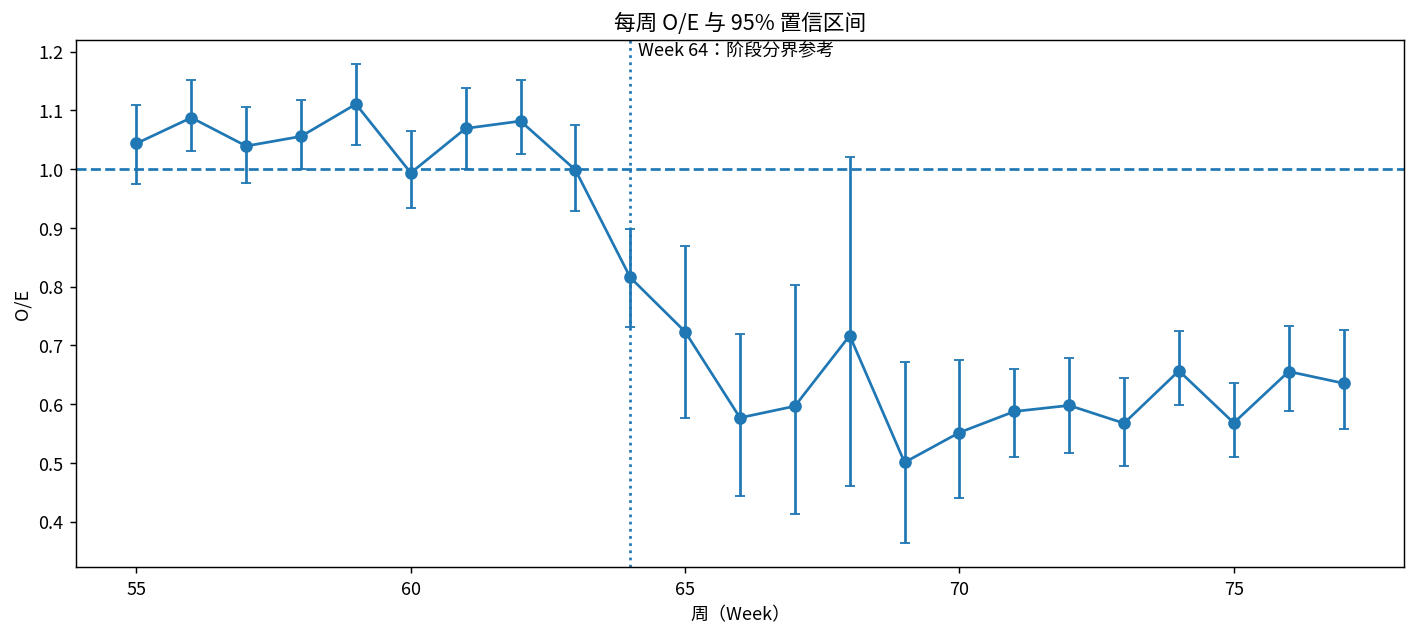

In [17]:
# ============================================================
# 13.2 图：每周 O/E + 95% CI
# ============================================================

plt.figure(figsize=(11, 5))

plt.errorbar(
    weekly_metrics[WEEK_COL],
    weekly_metrics["oe_ratio"],
    yerr=[
        weekly_metrics["oe_ratio"] - weekly_metrics["oe_ci_lower"],
        weekly_metrics["oe_ci_upper"] - weekly_metrics["oe_ratio"],
    ],
    marker="o",
    capsize=3,
)

plt.axhline(1.0, linestyle="--")
plt.axvline(64, linestyle=":")

if CHART_USE_CHINESE:
    plt.xlabel("周（Week）")
    plt.ylabel("O/E")
    plt.title("每周 O/E 与 95% 置信区间")
    plt.text(64.15, plt.ylim()[1], "Week 64：阶段分界参考", va="top")
else:
    plt.xlabel("Week")
    plt.ylabel("O/E")
    plt.title("Weekly O/E with 95% confidence intervals")
    plt.text(64.15, plt.ylim()[1], "Week 64: stage reference", va="top")

plt.tight_layout()
plt.show()

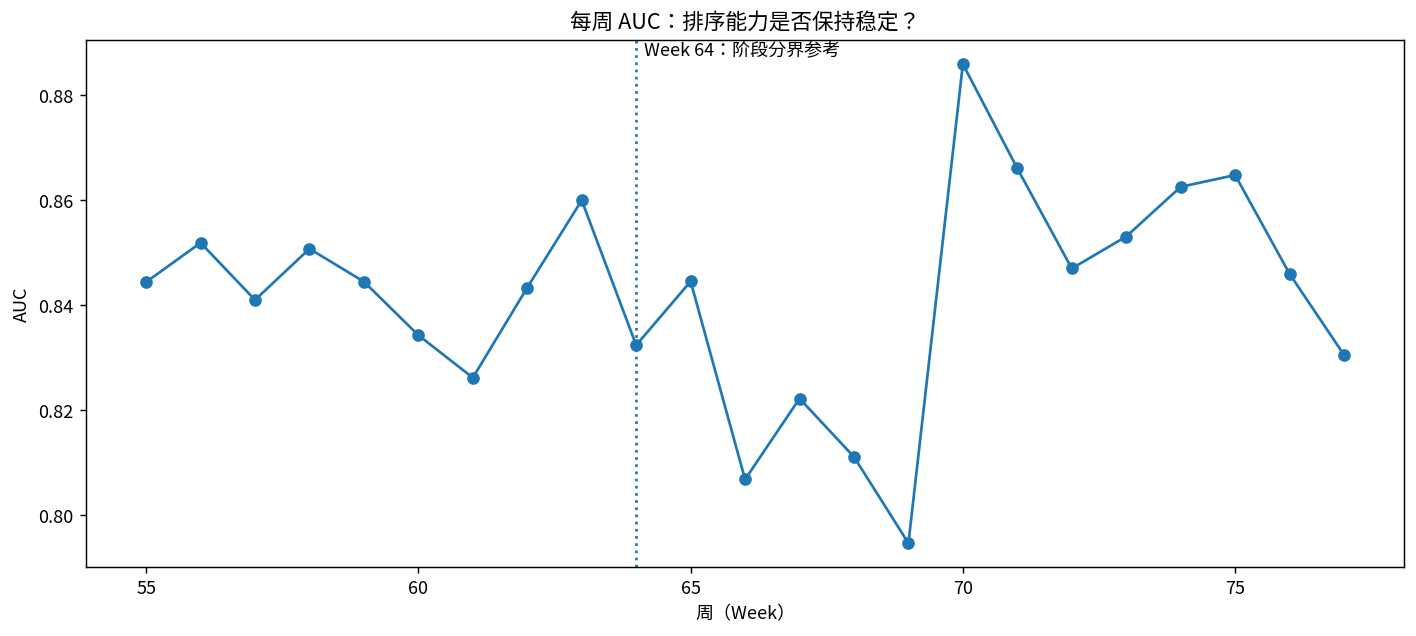

In [18]:
# ============================================================
# 13.3 图：每周 AUC
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    weekly_metrics[WEEK_COL],
    weekly_metrics["auc"],
    marker="o",
)

plt.axvline(64, linestyle=":")

if CHART_USE_CHINESE:
    plt.xlabel("周（Week）")
    plt.ylabel("AUC")
    plt.title("每周 AUC：排序能力是否保持稳定？")
    plt.text(64.15, plt.ylim()[1], "Week 64：阶段分界参考", va="top")
else:
    plt.xlabel("Week")
    plt.ylabel("AUC")
    plt.title("Weekly AUC: is ranking performance stable?")
    plt.text(64.15, plt.ylim()[1], "Week 64: stage reference", va="top")

plt.tight_layout()
plt.show()

# 14. 累积证据与等待期间的业务暴露

采用 Week 55 开始的 expanding window，计算每个累计终点的 O/E、置信区间与申请量。随着样本累积，不确定性通常会降低；与此同时，仍由模型处理的申请规模持续增加。

这里的累计申请量仅代表**业务暴露代理指标**，不表示发生了同等数量的错误决策，也不具有可直接解释为金额损失的单位。


In [19]:
# ============================================================
# 14.1 累积证据与累计业务暴露
# ============================================================

cumulative_rows = []

all_weeks = sorted(
    monitor_results[
        WEEK_COL
    ].unique()
)

for current_week in all_weeks:

    group = (
        monitor_results
        .loc[
            monitor_results[
                WEEK_COL
            ]
            .between(
                MONITOR_MIN_WEEK,
                current_week,
            )
        ]
        .copy()
    )

    metrics = basic_metrics(
        group
    )

    ci_low, ci_high = (
        bootstrap_oe_ci(
            group,
            rounds=300,
            seed=(
                RANDOM_SEED
                + 1000
                + int(
                    current_week
                )
            ),
        )
    )

    cumulative_rows.append({
        "start_week": (
            MONITOR_MIN_WEEK
        ),
        "current_week": int(
            current_week
        ),
        "weeks_observed": int(
            current_week
            - MONITOR_MIN_WEEK
            + 1
        ),
        "cumulative_applications": (
            len(group)
        ),
        **metrics,
        "oe_ci_lower": ci_low,
        "oe_ci_upper": ci_high,
        "oe_ci_excludes_1": bool(
            (
                ci_high < 1.0
            )
            or (
                ci_low > 1.0
            )
        ),
    })


cumulative_metrics = (
    pd.DataFrame(
        cumulative_rows
    )
)

cumulative_metrics.to_csv(
    REPORT_ROOT
    / "cumulative_monitoring_metrics.csv",
    index=False,
)

display(
    cumulative_metrics
)

,start_week,current_week,weeks_observed,cumulative_applications,sample_count,bad_count,observed_bad_rate,mean_predicted_pd,oe_ratio,auc,gini,calibration_slope,oe_ci_lower,oe_ci_upper,oe_ci_excludes_1
0,55,55,1,18538,18538,789,0.042561,0.040779,1.043716,0.844392,0.688783,1.006969,0.974127,1.110058,False
1,55,56,2,35610,35610,1600,0.044931,0.042169,1.065494,0.848275,0.696550,1.003485,1.022384,1.108889,True
2,55,57,3,53831,53831,2438,0.045290,0.042874,1.056338,0.845801,0.691601,0.995510,1.015424,1.090769,True
3,55,58,4,71650,71650,3305,0.046127,0.043673,1.056180,0.847080,0.694160,1.009805,1.021744,1.087581,True
4,55,59,5,89379,89379,4194,0.046924,0.043966,1.067271,0.846569,0.693138,1.014070,1.037556,1.096717,True
5,55,60,6,105243,105243,4923,0.046777,0.044311,1.055673,0.844731,0.689462,1.008903,1.028620,1.082952,True
6,55,61,7,120811,120811,5730,0.047429,0.044848,1.057570,0.842307,0.684615,0.999381,1.029709,1.081188,True
7,55,62,8,137975,137975,6625,0.048016,0.045265,1.060774,0.842501,0.685002,1.003081,1.036258,1.083988,True
8,55,63,9,152312,152312,7214,0.047363,0.044877,1.055412,0.844085,0.688169,1.007828,1.032985,1.076240,True
9,55,64,10,162580,162580,7536,0.046353,0.044471,1.042315,0.843908,0.687816,1.003762,1.022624,1.064843,True


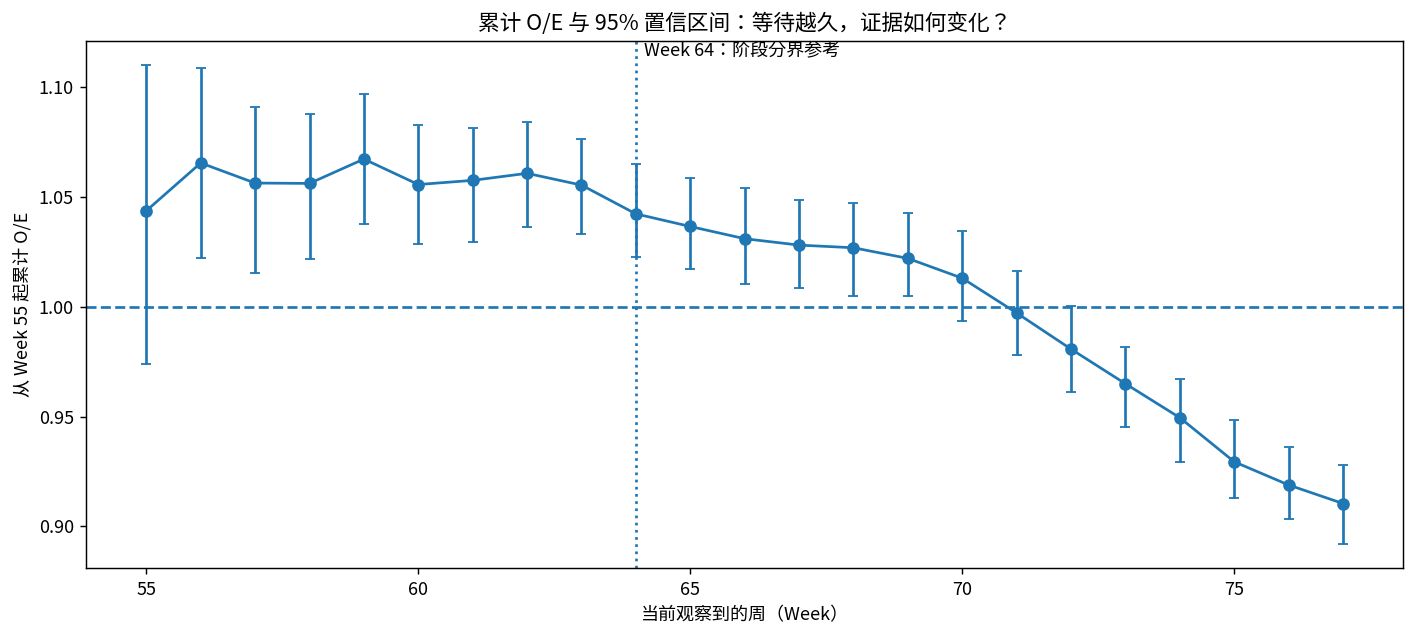

In [20]:
# ============================================================
# 14.2 图：累计 O/E 的证据如何变化？
# ============================================================

plt.figure(figsize=(11, 5))

plt.errorbar(
    cumulative_metrics["current_week"],
    cumulative_metrics["oe_ratio"],
    yerr=[
        cumulative_metrics["oe_ratio"] - cumulative_metrics["oe_ci_lower"],
        cumulative_metrics["oe_ci_upper"] - cumulative_metrics["oe_ratio"],
    ],
    marker="o",
    capsize=3,
)

plt.axhline(1.0, linestyle="--")
plt.axvline(64, linestyle=":")

if CHART_USE_CHINESE:
    plt.xlabel("当前观察到的周（Week）")
    plt.ylabel("从 Week 55 起累计 O/E")
    plt.title("累计 O/E 与 95% 置信区间：等待越久，证据如何变化？")
    plt.text(64.15, plt.ylim()[1], "Week 64：阶段分界参考", va="top")
else:
    plt.xlabel("Current week observed")
    plt.ylabel("Cumulative O/E from Week 55")
    plt.title("Cumulative O/E with 95% confidence intervals")
    plt.text(64.15, plt.ylim()[1], "Week 64: stage reference", va="top")

plt.tight_layout()
plt.show()

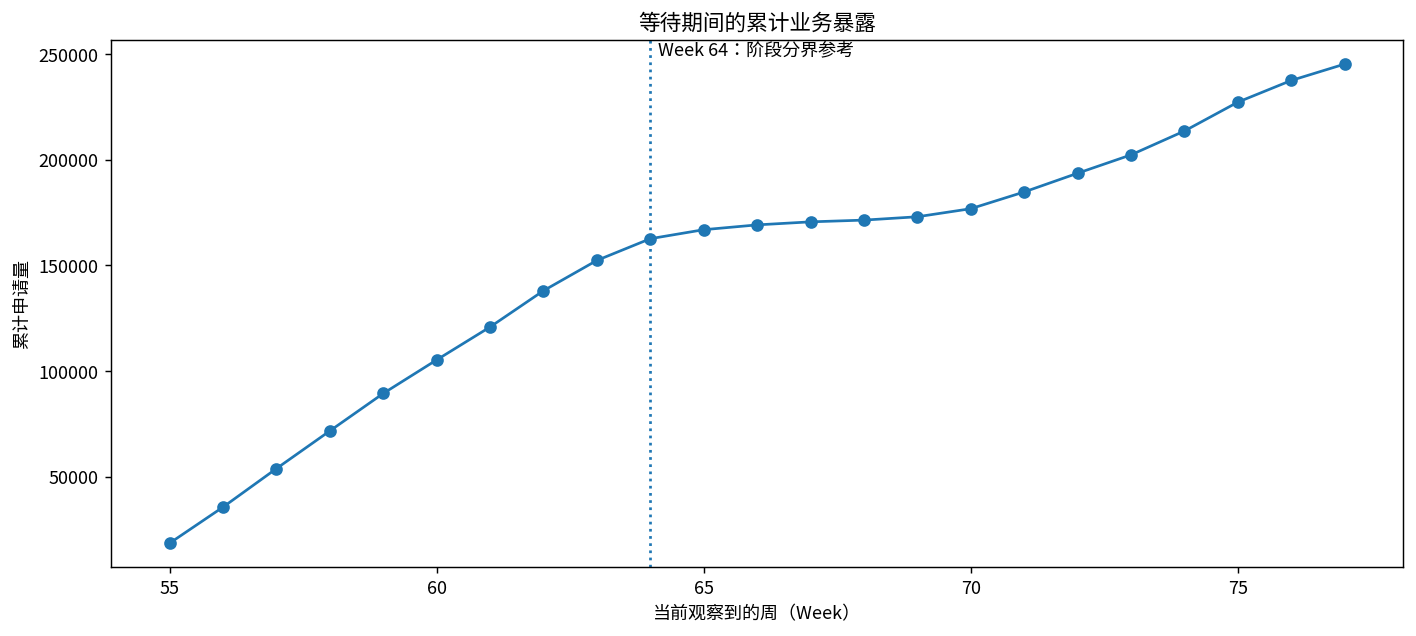

In [21]:
# ============================================================
# 14.3 图：等待越久，累计经过模型的申请越多
# ============================================================

plt.figure(figsize=(11, 5))

plt.plot(
    cumulative_metrics["current_week"],
    cumulative_metrics["cumulative_applications"],
    marker="o",
)

plt.axvline(64, linestyle=":")

if CHART_USE_CHINESE:
    plt.xlabel("当前观察到的周（Week）")
    plt.ylabel("累计申请量")
    plt.title("等待期间的累计业务暴露")
    plt.text(64.15, plt.ylim()[1], "Week 64：阶段分界参考", va="top")
else:
    plt.xlabel("Current week observed")
    plt.ylabel("Cumulative applications")
    plt.title("Cumulative business exposure while waiting")
    plt.text(64.15, plt.ylim()[1], "Week 64: stage reference", va="top")

plt.tight_layout()
plt.show()

# 15. 统计异常信号与业务复核的区别

单周 O/E 的 95% CI 排除 1，意味着在所用统计假设和重抽样方法下，完全校准与当前数据不太相容；但这并不自动证明产生了特定形式的概念漂移，也不直接给出停用模型的业务决策。

复核政策仍需综合考虑偏离幅度、持续时间、业务重要性、观察延迟及其他数据质量诊断。下方代码仅标记统计异常的出现时间，不将其直接命名为生产报警。


In [22]:
# ============================================================
# 15.1 描述第一处统计信号，不把它包装成业务报警
# ============================================================

weekly_signal_rows = (
    weekly_metrics
    .loc[
        weekly_metrics[
            "oe_ci_excludes_1"
        ]
    ]
)

cumulative_signal_rows = (
    cumulative_metrics
    .loc[
        cumulative_metrics[
            "oe_ci_excludes_1"
        ]
    ]
)

if len(
    weekly_signal_rows
) > 0:

    first_weekly_signal = (
        int(
            weekly_signal_rows[
                WEEK_COL
            ]
            .iloc[0]
        )
    )

    print(
        "第一处单周统计异常信号：Week",
        first_weekly_signal,
    )

else:

    first_weekly_signal = None

    print(
        "Week 55–77 没有出现"
        "O/E CI 排除 1 的单周信号。"
    )


if len(
    cumulative_signal_rows
) > 0:

    first_cumulative_signal = (
        int(
            cumulative_signal_rows[
                "current_week"
            ]
            .iloc[0]
        )
    )

    first_cumulative_exposure = (
        int(
            cumulative_signal_rows[
                "cumulative_applications"
            ]
            .iloc[0]
        )
    )

    print(
        "第一处累计统计异常信号：Week",
        first_cumulative_signal,
    )

    print(
        "此时从 Week 55 起累计申请量：",
        f"{first_cumulative_exposure:,}",
    )

else:

    first_cumulative_signal = None

    print(
        "累计窗口没有出现"
        "O/E CI 排除 1 的信号。"
    )

第一处单周统计异常信号：Week 56
第一处累计统计异常信号：Week 56
此时从 Week 55 起累计申请量： 35,610


# 16. 两个历史阶段的 Calibration Plot

为比较校准变化，分别汇总 Week 55–63 与 Week 64–77 的预测违约概率和实际违约率，并绘制风险分组校准图。

这两段划分用于**事后比较**，不代表在实际部署时已经知道 Week 64 是真实漂移起点。


,risk_group,sample_count,mean_predicted_pd,observed_bad_rate
0,"(-0.00071, 0.00276]",15232,0.001776,0.000657
1,"(0.00276, 0.00501]",15231,0.003834,0.002101
2,"(0.00501, 0.00801]",15231,0.006434,0.003611
3,"(0.00801, 0.0122]",15231,0.009971,0.009651
4,"(0.0122, 0.0181]",15231,0.014968,0.015757
5,"(0.0181, 0.0271]",15231,0.022291,0.024424
6,"(0.0271, 0.0413]",15231,0.033578,0.038605
7,"(0.0413, 0.0658]",15231,0.052210,0.057252
8,"(0.0658, 0.118]",15231,0.087967,0.098877
9,"(0.118, 0.873]",15232,0.215729,0.222689


,risk_group,sample_count,mean_predicted_pd,observed_bad_rate
0,"(-0.000598, 0.00318]",9287,0.002148,0.001184
1,"(0.00318, 0.0052]",9287,0.004165,0.002154
2,"(0.0052, 0.00769]",9287,0.006400,0.003015
3,"(0.00769, 0.0109]",9287,0.009232,0.003230
4,"(0.0109, 0.0156]",9287,0.013142,0.005384
5,"(0.0156, 0.0226]",9287,0.018826,0.010122
6,"(0.0226, 0.0338]",9287,0.027679,0.015829
7,"(0.0338, 0.0538]",9287,0.042699,0.029396
8,"(0.0538, 0.0985]",9287,0.072712,0.047270
9,"(0.0985, 0.844]",9287,0.186920,0.125229


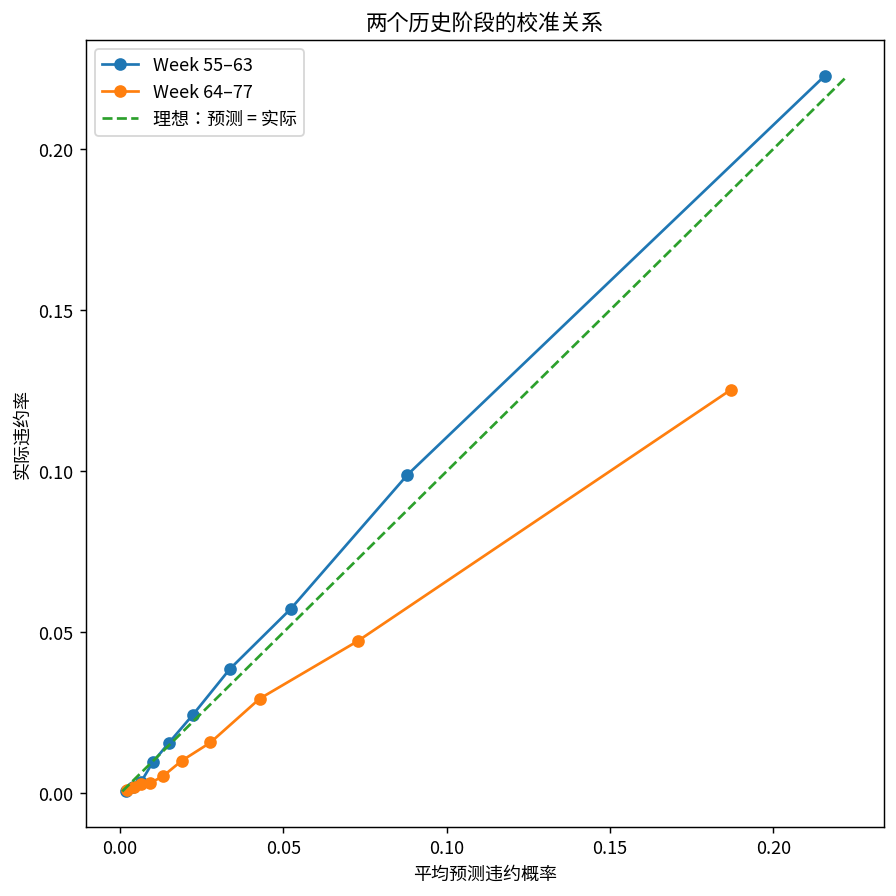

In [23]:
# ============================================================
# 16.1 两阶段 Calibration Plot
# ============================================================

def calibration_table(
    frame,
    bins=10,
):
    temp = (
        frame[
            [
                TARGET_COL,
                "predicted_pd",
            ]
        ]
        .copy()
    )

    temp[
        "risk_group"
    ] = pd.qcut(
        temp[
            "predicted_pd"
        ],
        q=bins,
        duplicates="drop",
    )

    return (
        temp
        .groupby(
            "risk_group",
            observed=True,
        )
        .agg(
            sample_count=(
                TARGET_COL,
                "size",
            ),
            mean_predicted_pd=(
                "predicted_pd",
                "mean",
            ),
            observed_bad_rate=(
                TARGET_COL,
                "mean",
            ),
        )
        .reset_index()
    )


stage_55_63 = (
    monitor_results
    .loc[
        monitor_results[
            WEEK_COL
        ].between(
            55,
            63,
        )
    ]
)

stage_64_77 = (
    monitor_results
    .loc[
        monitor_results[
            WEEK_COL
        ].between(
            64,
            77,
        )
    ]
)

calib_55_63 = (
    calibration_table(
        stage_55_63
    )
)

calib_64_77 = (
    calibration_table(
        stage_64_77
    )
)

display(
    calib_55_63
)

display(
    calib_64_77
)

plt.figure(figsize=(7, 7))

plt.plot(
    calib_55_63["mean_predicted_pd"],
    calib_55_63["observed_bad_rate"],
    marker="o",
    label="Week 55–63",
)

plt.plot(
    calib_64_77["mean_predicted_pd"],
    calib_64_77["observed_bad_rate"],
    marker="o",
    label="Week 64–77",
)

all_x = np.concatenate([
    calib_55_63["mean_predicted_pd"].to_numpy(),
    calib_64_77["mean_predicted_pd"].to_numpy(),
])

all_y = np.concatenate([
    calib_55_63["observed_bad_rate"].to_numpy(),
    calib_64_77["observed_bad_rate"].to_numpy(),
])

low = float(min(all_x.min(), all_y.min()))
high = float(max(all_x.max(), all_y.max()))

plt.plot(
    [low, high],
    [low, high],
    linestyle="--",
    label=("理想：预测 = 实际" if CHART_USE_CHINESE else "Ideal: predicted = observed"),
)

if CHART_USE_CHINESE:
    plt.xlabel("平均预测违约概率")
    plt.ylabel("实际违约率")
    plt.title("两个历史阶段的校准关系")
else:
    plt.xlabel("Mean predicted default probability")
    plt.ylabel("Observed default rate")
    plt.title("Calibration across two historical periods")

plt.legend()
plt.tight_layout()
plt.show()

# 17. 运行结果与解释范围

保存的运行结果显示：

| 时间段 | 样本数 | O/E | AUC | Calibration Slope |
|---|---:|---:|---:|---:|
| Week 55–63 | 152,312 | 1.0554 | 0.8441 | 1.0078 |
| Week 64–77 | 92,870 | 0.6325 | 0.8485 | 1.0415 |
| Week 55–77 | 245,182 | 0.9104 | 0.8475 | 1.0250 |

此结果表明：两个阶段的 AUC 都在 0.84 左右，但后期 O/E 明显低于 1，提示整体预测风险水平高于观测结果；因此需要把概率校准与排序能力分别评价。

**解释边界：** 保存的程序还将 Week 56 记为第一处单周和累积 O/E 统计异常信号。这说明早期阶段并非每一周都严格无偏；Week 64 附近的阶段性变化不应被简化成“此前完全正常、此后才出现任何异常”。单一历史事件不足以独立验证未来报警规则的误报率或泛化能力。


In [24]:
# ============================================================
# 17.1 自动打印关键摘要并保存实验元数据
# ============================================================

summary_rows = []

for label, frame in [
    (
        "Week 55-63",
        stage_55_63,
    ),
    (
        "Week 64-77",
        stage_64_77,
    ),
    (
        "Week 55-77",
        monitor_results,
    ),
]:

    metrics = basic_metrics(
        frame
    )

    summary_rows.append({
        "period": label,
        **metrics,
    })


period_summary = pd.DataFrame(
    summary_rows
)

period_summary.to_csv(
    REPORT_ROOT
    / "period_summary.csv",
    index=False,
)

display(
    period_summary
)

experiment_metadata = {
    "dev_train": "Week 0-49",
    "dev_stop": "Week 50-54",
    "deploy_train": "Week 0-54",
    "monitor": "Week 55-77",
    "oot": "Week 78-91 untouched",
    "best_iteration": (
        BEST_ITERATION
    ),
    "lightgbm_params": (
        LGBM_PARAMS
    ),
    "first_weekly_oe_statistical_signal": (
        first_weekly_signal
    ),
    "first_cumulative_oe_statistical_signal": (
        first_cumulative_signal
    ),
}

with open(
    REPORT_ROOT
    / "experiment_metadata.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        experiment_metadata,
        f,
        ensure_ascii=False,
        indent=2,
    )

print()
print(
    "历史回测输出已经保存到："
)

print(
    REPORT_ROOT
)

,period,sample_count,bad_count,observed_bad_rate,mean_predicted_pd,oe_ratio,auc,gini,calibration_slope
0,Week 55-63,152312,7214,0.047363,0.044877,1.055412,0.844085,0.688169,1.007828
1,Week 64-77,92870,2255,0.024281,0.038392,0.632451,0.848491,0.696983,1.041523
2,Week 55-77,245182,9469,0.038620,0.042420,0.910416,0.847459,0.694919,1.025044



历史回测输出已经保存到：
/content/drive/MyDrive/HomeCredit_Project/artifacts/fit5145/nb02_history_backtest
